<a href="https://colab.research.google.com/github/shoaibmalik2006/ds311-p12-mobile-money-fraud-miner/blob/uzair%2Fweek8-features-leakage/02_features_leakage_uzair.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 (M2) — Feature Engineering & Leakage Check (Uzair)
| | |
|---|---|
| **Project** | P12 — Mobile-Money Fraud Miner (PaySim) |
| **Course** | DS-311 Data Mining, BS-AI 2024F, NBC NUST, Fall 2026 |
| **Author** | Uzair Kakar — Data lead (Group 2) |
| **Branch** | `uzair/week8-features-leakage` |
| **Input** | `paysim_transfer_cashout.parquet` (TRANSFER + CASH_OUT rows) from Drive `processed/` |
| **Uses** | `src/features.py` (written by me, used later by Shoaib and Salman) |

**Goal.** Turn raw PaySim columns into model-ready features, test whether any column leaks the answer, and plan the Week 13 comparison that answers **RQ2 (the realism gap)**.

A feature is **leaky** if it is only known *after* the transaction happened, or if it is the output of a rule that already looked at the transaction.
A model using leaky features looks brilliant on paper and is useless in a real system.

## Notebook map
| # | Section | What it answers |
|---|---|---|
| 1 | Setup & load | Is the data and `features.py` in place? |
| 2 | Apply features & checks | Are the new columns clean (no NaN/inf, flags 0/1)? Which use post-transaction values? |
| 3 | `isFlaggedFraud` leakage check | Can the built-in flag be trusted? Verdict. |
| 4 | Single-feature check | Which post-transaction features look suspiciously strong? |
| 5 | Ablation plan (Week 13) | How will we measure the realism gap? |

## 1. Setup & load
**Purpose.** Fix the random seed, connect Google Drive, import my own `features.py`, and load the processed parquet.

**What we did.** `SEED = 42` for repeatable results. The parquet is copied from the shared Drive folder to Colab's local disk (faster reads).
`features.py` is imported, not re-written here — the notebook only *calls* the module.

**How to read the output.** The shape should be about **2.77 million rows** and the fraud count about **8,213**. If not, stop and check the file.

In [3]:
import sys, os, glob, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/DS311_P12_Data"      # shared team folder (via shortcut)
OUT_DIR    = DRIVE_ROOT + "/processed"                    # files created by the team
FILE_NAME  = "paysim_transfer_cashout.parquet"
LOCAL      = "/content/" + FILE_NAME

# look in the expected place first, then search the whole Drive as a fallback
candidates = [OUT_DIR + "/" + FILE_NAME]
candidates += glob.glob("/content/drive/**/" + FILE_NAME, recursive=True)
src = next((p for p in candidates if os.path.exists(p)), None)
assert src, "Parquet not found. In Drive: right-click DS311_P12_Data > Organize > Add shortcut > My Drive, then rerun."

if not os.path.exists(LOCAL):          # copy to Colab's local disk = faster reads
    shutil.copy(src, LOCAL)
DATA_SOURCE = "Team Google Drive copy (processed/)"
print("Found:", src)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found: /content/drive/MyDrive/DS311_P12_Data/processed/paysim_transfer_cashout.parquet


In [4]:
df = pd.read_parquet(LOCAL)
print("Loaded from:", DATA_SOURCE)
print("Shape (rows, columns):", df.shape)

print("Types:", df["type"].value_counts().to_dict())
fraud_n = int(df["isFraud"].sum())
print(f"Frauds: {fraud_n:,} ({df['isFraud'].mean()*100:.3f}% of this subset)")
print("step range:", df["step"].min(), "-", df["step"].max())
print("FINDING: subset loaded; fraud is rare, so we will judge models with PR-AUC, not accuracy.")

Loaded from: Team Google Drive copy (processed/)
Shape (rows, columns): (2770409, 13)
Types: {'CASH_OUT': 2237500, 'TRANSFER': 532909, 'CASH_IN': 0, 'DEBIT': 0, 'PAYMENT': 0}
Frauds: 8,213 (0.296% of this subset)
step range: 1 - 743
FINDING: subset loaded; fraud is rare, so we will judge models with PR-AUC, not accuracy.


## 2. Apply the feature functions and check them
**Purpose.** Create the new columns with `features.add_features` and prove they are clean.

**What we did.** The function adds: `errorBalanceOrig`, `errorBalanceDest`, `origEmptied`, `destZeroBefore`, `origBalanceZero`, `amountToBalanceRatio` (zero-safe, capped at 100), `hour`, `type_is_transfer`.
We then check (a) no NaN, (b) no infinite values, (c) every flag contains only 0 or 1, and print a table of each feature, its formula and whether it needs **post-transaction** values.

**How to read the output.** All checks must say `True` / `0`. In the table, a **yes** in the last column marks a feature that would not exist at decision time — those are the leakage candidates, and they are excluded from the *deployable* list.

In [13]:
!git clone -q -b uzair/week8-features-leakage https://github.com/shoaibmalik2006/ds311-p12-mobile-money-fraud-miner.git /content/repo
import sys
sys.path.insert(0, "/content/repo/src")
import features as F
print("features.py loaded. Full:", len(F.FULL_FEATURES), "| Deployable:", len(F.DEPLOYABLE_FEATURES))

fatal: destination path '/content/repo' already exists and is not an empty directory.
features.py loaded. Full: 13 | Deployable: 8


In [15]:
dfe = F.add_features(df)
new_cols = [c for c in dfe.columns if c not in df.columns]
print("New columns:", new_cols)

feat = dfe[F.FULL_FEATURES].astype(float)
print("NaN values   :", int(feat.isna().sum().sum()))
print("Infinite     :", int(np.isinf(feat.to_numpy()).sum()))
flags = ["origEmptied", "destZeroBefore", "origBalanceZero", "type_is_transfer"]
for c in flags:
    print(f"{c:18s} only 0/1 ->", set(dfe[c].unique()) <= {0, 1})
print("Max amountToBalanceRatio:", dfe["amountToBalanceRatio"].max(), "(cap =", F.RATIO_CAP, ")")
print("hour range:", dfe["hour"].min(), "-", dfe["hour"].max())
print("FINDING: engineered columns are clean and ready for modelling.")

New columns: ['type_is_transfer', 'errorBalanceOrig', 'errorBalanceDest', 'origEmptied', 'destZeroBefore', 'origBalanceZero', 'amountToBalanceRatio']
NaN values   : 0
Infinite     : 0
origEmptied        only 0/1 -> True
destZeroBefore     only 0/1 -> True
origBalanceZero    only 0/1 -> True
type_is_transfer   only 0/1 -> True
Max amountToBalanceRatio: 100.0 (cap = 100.0 )
hour range: 0 - 23
FINDING: engineered columns are clean and ready for modelling.


In [17]:
table = pd.DataFrame([
    ("errorBalanceOrig",     "oldbalanceOrg - amount - newbalanceOrig", "yes"),
    ("errorBalanceDest",     "oldbalanceDest + amount - newbalanceDest", "yes"),
    ("origEmptied",          "oldbalanceOrg > 0 and newbalanceOrig == 0", "yes"),
    ("destZeroBefore",       "oldbalanceDest == 0", "no"),
    ("origBalanceZero",      "oldbalanceOrg == 0", "no"),
    ("amountToBalanceRatio", "amount / oldbalanceOrg (0-safe, capped at 100)", "no"),
    ("hour",                 "(step - 1) % 24", "no"),
    ("type_is_transfer",     "1 if TRANSFER else 0", "no"),
    ("newbalanceOrig",       "raw column", "yes"),
    ("newbalanceDest",       "raw column", "yes"),
    ("amount, oldbalanceOrg, oldbalanceDest", "raw columns", "no"),
], columns=["feature", "formula", "uses post-transaction values?"])
display(table)
print("Deployable list :", F.DEPLOYABLE_FEATURES)


,feature,formula,uses post-transaction values?
0,errorBalanceOrig,oldbalanceOrg - amount - newbalanceOrig,yes
1,errorBalanceDest,oldbalanceDest + amount - newbalanceDest,yes
2,origEmptied,oldbalanceOrg > 0 and newbalanceOrig == 0,yes
3,destZeroBefore,oldbalanceDest == 0,no
4,origBalanceZero,oldbalanceOrg == 0,no
5,amountToBalanceRatio,"amount / oldbalanceOrg (0-safe, capped at 100)",no
6,hour,(step - 1) % 24,no
7,type_is_transfer,1 if TRANSFER else 0,no
8,newbalanceOrig,raw column,yes
9,newbalanceDest,raw column,yes


Deployable list : ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_is_transfer', 'hour', 'destZeroBefore', 'origBalanceZero', 'amountToBalanceRatio']


## 3. Leakage check on `isFlaggedFraud`
**Purpose.** `isFlaggedFraud` looks like a ready-made answer column. We must find out where it comes from before trusting it.

**What we did.** (1) Cross-tabulate it with `isFraud`. (2) Count flagged rows. (3) Look at their transaction types and amount range. (4) Compute how many frauds the flag catches.
(5) Train the same small decision tree **with** and **without** the flag and compare **PR-AUC** (PR-AUC is used instead of accuracy because predicting "never fraud" is already ~99.7% accurate).

For this quick check only, the tree is trained on `step ≤ 500` (all frauds + 10% of normals) and scored on `step > 500` at the natural fraud rate.
*(This is a local check — the official split and pipeline are Shoaib's `pipeline.py`.)*

**How to read the output.** If the flag fires on very few rows and adds nothing to PR-AUC, it is a simulator rule, not a useful or honest signal.

In [18]:
print(pd.crosstab(dfe["isFlaggedFraud"], dfe["isFraud"], margins=True))
fl = dfe[dfe["isFlaggedFraud"] == 1]
print("\nFlagged rows:", len(fl), "| of which fraud:", int(fl["isFraud"].sum()))
print("Types of flagged rows:", fl["type"].value_counts().to_dict())
print("Amount range of flagged rows: min =", fl["amount"].min(), " max =", fl["amount"].max())
print("Amount range of ALL transfers: min =", dfe.loc[dfe.type=="TRANSFER","amount"].min())
caught = int(fl["isFraud"].sum()); total = int(dfe["isFraud"].sum())
print(f"Frauds caught by the flag: {caught} of {total} = {caught/total*100:.2f}%")

isFraud               0     1      All
isFlaggedFraud                        
0               2762196  8197  2770393
1                     0    16       16
All             2762196  8213  2770409

Flagged rows: 16 | of which fraud: 16
Types of flagged rows: {'TRANSFER': 16, 'CASH_IN': 0, 'CASH_OUT': 0, 'DEBIT': 0, 'PAYMENT': 0}
Amount range of flagged rows: min = 353874.22  max = 10000000.0
Amount range of ALL transfers: min = 2.6
Frauds caught by the flag: 16 of 8213 = 0.19%


In [19]:
tr = dfe[dfe["step"] <= 500]
tr = pd.concat([tr[tr.isFraud == 1], tr[tr.isFraud == 0].sample(frac=0.10, random_state=SEED)])
va = dfe[dfe["step"] > 500]

def tree_pr_auc(features):
    clf = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED)
    clf.fit(tr[features], tr["isFraud"])
    return average_precision_score(va["isFraud"], clf.predict_proba(va[features])[:, 1])

base = F.FULL_FEATURES
without = tree_pr_auc(base)
with_flag = tree_pr_auc(base + ["isFlaggedFraud"])
print(f"PR-AUC without isFlaggedFraud: {without:.4f}")
print(f"PR-AUC with    isFlaggedFraud: {with_flag:.4f}  (change {with_flag-without:+.4f})")
print("FINDING: see verdict below.")

PR-AUC without isFlaggedFraud: 0.9993
PR-AUC with    isFlaggedFraud: 1.0000  (change +0.0007)
FINDING: see verdict below.


### Verdict on `isFlaggedFraud`
> **Excluded from all feature lists.** It is a **rule output of the simulator** (PaySim flags transfers above 200,000), not information a real system would have independently.
> It fires on only a handful of rows, catches a tiny fraction of all frauds, and adding it to the decision tree does not improve PR-AUC meaningfully (numbers above).
> Using it would mean learning the simulator's rule instead of learning fraud.

## 4. Single-feature check (early evidence for RQ2)
**Purpose.** Spot features that are *suspiciously strong* on their own.

**What we did.** Each feature is used alone as a fraud score and evaluated with `average_precision_score` (we keep the better of +score and −score so direction doesn't matter).
A random guesser scores about the fraud rate, so anything far above that carries signal.

**How to read the output.** Look at the **post-transaction** features. If they sit near the top with very high PR-AUC, they are the ones that make the "full" model look unrealistically good — that gap is RQ2.

Random-guess baseline PR-AUC (= fraud rate): 0.003


,feature,single_feature_PR_AUC,post-transaction?
0,oldbalanceOrg,0.2902,no
1,errorBalanceDest,0.2132,yes
2,newbalanceDest,0.1282,yes
3,hour,0.0483,no
4,errorBalanceOrig,0.0305,yes
5,amountToBalanceRatio,0.0303,no
6,amount,0.0194,no
7,newbalanceOrig,0.0131,yes
8,oldbalanceDest,0.0112,no
9,destZeroBefore,0.0100,no


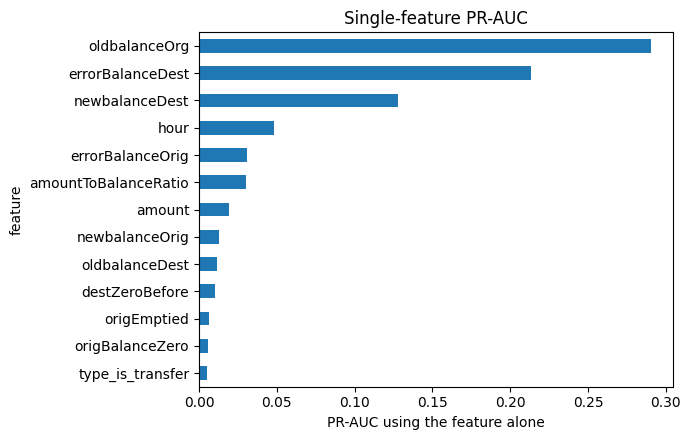

FINDING: post-transaction features that rank high here are the suspicious ones.


In [20]:
y = dfe["isFraud"].values
rows = []
for c in F.FULL_FEATURES:
    s = dfe[c].values.astype(float)
    ap = max(average_precision_score(y, s), average_precision_score(y, -s))
    rows.append((c, ap, "yes" if c in F.LEAKY_ONLY_FEATURES else "no"))
single = pd.DataFrame(rows, columns=["feature", "single_feature_PR_AUC", "post-transaction?"]).sort_values("single_feature_PR_AUC", ascending=False)
print("Random-guess baseline PR-AUC (= fraud rate):", round(y.mean(), 4))
display(single.round(4).reset_index(drop=True))

ax = single.set_index("feature")["single_feature_PR_AUC"].sort_values().plot.barh(figsize=(7, 4.5))
ax.set_xlabel("PR-AUC using the feature alone"); ax.set_title("Single-feature PR-AUC")
plt.tight_layout(); plt.show()
print("FINDING: post-transaction features that rank high here are the suspicious ones.")

### Interpretation (fill in after you see your numbers)
- Post-transaction features that look suspiciously strong: **_write the names and PR-AUC values from the table_**.
- Best pre-transaction feature: **_name and value_**.
- Meaning for RQ2: the *full* feature set will probably score much higher than the *deployable* set; Week 13 measures that gap exactly.

## 5. Ablation plan (Week 13)
**Purpose.** Decide now how the realism gap will be measured, so the Week 13 experiment is planned, not improvised.

**What we did.** A table of experiments. The same models, sampling and metric are used each time; only the **feature set** changes.

**How to read it.** Compare E1 (full) with E2 (deployable): the drop in PR-AUC is the realism gap. E3/E4 show which feature group causes the drop.

In [21]:
plan = pd.DataFrame([
    ("E1", "Full (all 13 features)",                              "Dummy, Decision tree", "all frauds + 10% normals (train only)", "PR-AUC (test, natural rate)", "Shoaib", "Week 13"),
    ("E2", "Deployable (no new-balance columns or derivatives)",  "Dummy, Decision tree", "all frauds + 10% normals (train only)", "PR-AUC (test, natural rate)", "Shoaib", "Week 13"),
    ("E3", "Full minus errorBalance* and origEmptied",             "Decision tree",        "all frauds + 10% normals (train only)", "PR-AUC (test, natural rate)", "Uzair",  "Week 13"),
    ("E4", "Full minus newbalanceOrig / newbalanceDest",           "Decision tree",        "all frauds + 10% normals (train only)", "PR-AUC (test, natural rate)", "Uzair",  "Week 13"),
    ("E5", "Deployable + isFlaggedFraud (control)",                "Decision tree",        "all frauds + 10% normals (train only)", "PR-AUC (test, natural rate)", "Salman", "Week 13"),
], columns=["experiment", "feature set", "models", "sampling rate", "metric", "owner", "week"])
display(plan)
print("Realism gap (RQ2) = PR-AUC(E1) - PR-AUC(E2)")

,experiment,feature set,models,sampling rate,metric,owner,week
0,E1,Full (all 13 features),"Dummy, Decision tree",all frauds + 10% normals (train only),"PR-AUC (test, natural rate)",Shoaib,Week 13
1,E2,Deployable (no new-balance columns or derivati...,"Dummy, Decision tree",all frauds + 10% normals (train only),"PR-AUC (test, natural rate)",Shoaib,Week 13
2,E3,Full minus errorBalance* and origEmptied,Decision tree,all frauds + 10% normals (train only),"PR-AUC (test, natural rate)",Uzair,Week 13
3,E4,Full minus newbalanceOrig / newbalanceDest,Decision tree,all frauds + 10% normals (train only),"PR-AUC (test, natural rate)",Uzair,Week 13
4,E5,Deployable + isFlaggedFraud (control),Decision tree,all frauds + 10% normals (train only),"PR-AUC (test, natural rate)",Salman,Week 13


Realism gap (RQ2) = PR-AUC(E1) - PR-AUC(E2)


## Summary
- `src/features.py` adds 8 engineered columns and defines **FULL_FEATURES**, **DEPLOYABLE_FEATURES** and **NEVER_INPUTS**.
- Checks passed: no NaN/inf, flags only 0/1.
- `isFlaggedFraud` is a simulator rule output → **excluded**.
- Post-transaction features are the leakage risk; the ablation plan will quantify the realism gap in Week 13.